# Burnout Risk Classification with a Neural Network
This notebook builds a 3-class neural network (Low / Moderate / High) to predict `Burnout_Risk` from workplace and lifestyle features. Steps: load & explore data, test features for significance, preprocess, train a neural net, and evaluate on a held-out test set.

In [11]:
# Import libraries for data handling, visualization, statistics, and modeling
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from scipy.stats import chi2_contingency   # test of association between two categorical variables
from scipy.stats import kruskal            # non-parametric test to compare a numeric variable across groups
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import classification_report

## 1. Load the Data

In [12]:
# Load the raw dataset from CSV into a DataFrame
mental_df = pd.read_csv('/kaggle/input/datasets/mobeenfatimah/mental-health-and-burnout-prediction-dataset/mental_health_burnout_prediction_dataset.csv')

In [13]:
# Preview the first 5 rows to get a feel for the columns and data
mental_df.head()

,Person_ID,Age,Gender,Country,Occupation,Education_Level,Employment_Status,Monthly_Income_USD,Work_Hours_Per_Week,Remote_Work,...,Family_History_Mental_Illness,Therapy_Attendance,Support_System,Life_Satisfaction,Productivity_Score,Absenteeism_Days,Burnout_Score,Mental_Health_Status,AI_Wellness_Recommendation,Burnout_Risk
0,1,58.0,Male,United States,Marketing Manager,Diploma,Employed,2786.0,67,Hybrid,...,No,Yes,Average,6.0,19.0,2,82,Critical,Practice Mindfulness,High
1,2,24.0,Female,Pakistan,Freelancer,Bachelor,Student,8027.0,44,Hybrid,...,Yes,No,Good,4.0,27.0,22,64,Critical,Reduce Workload,Moderate
2,3,59.0,Male,Malaysia,Accountant,PhD,Employed,3177.0,60,No,...,Yes,No,Average,4.0,51.0,17,50,Needs Attention,Increase Physical Activity,Moderate
3,4,65.0,Other,Mexico,Chef,Master,Self-Employed,4093.0,25,Yes,...,No,Yes,Good,7.0,83.0,14,16,Healthy,Maintain Healthy Routine,Low
4,5,64.0,Other,Japan,Farmer,Diploma,Student,NaN,52,No,...,Yes,No,Poor,9.0,61.0,4,26,Healthy,Reduce Workload,Low


## 2. Explore the Data
Check shape, types, missing values, duplicates, and basic distributions.

In [14]:
def basic_df_checks(df):
    # Quick, reusable health-check for any DataFrame: shape, dtypes, missing values,
    # duplicates, and summary stats for both numeric and categorical columns
    print("=== BASIC DATAFRAME CHECKS ===")
    print(f"Shape: {df.shape[0]} rows × {df.shape[1]} columns\n")

    print("Column Data Types:")
    print(df.dtypes)
    print("\nMissing Values:")
    print(df.isnull().sum())
    print("\nDuplicate Rows:", df.duplicated().sum())

    print("\n=== NUMERIC SUMMARY ===")
    display(df.describe(include=[np.number]))

    print("\n=== CATEGORICAL SUMMARY ===")
    display(df.describe(include=['object', 'category']).T)

    print("\nUnique Values per Column:")
    for col in df.columns:
        print(f"{col}: {df[col].nunique()}")

# Run the checks on the burnout dataset
basic_df_checks(mental_df)

=== BASIC DATAFRAME CHECKS ===
Shape: 50000 rows × 40 columns

Column Data Types:
Person_ID                          int64
Age                              float64
Gender                            object
Country                           object
Occupation                        object
Education_Level                   object
Employment_Status                 object
Monthly_Income_USD               float64
Work_Hours_Per_Week                int64
Remote_Work                       object
Job_Satisfaction                 float64
Work_Life_Balance                float64
Sleep_Hours                      float64
Sleep_Quality                     object
Stress_Level                      object
Anxiety_Score                    float64
Depression_Score                 float64
Mood_Score                       float64
Emotional_Stability                int64
Physical_Activity_Hours          float64
Exercise_Frequency                object
Meditation_Minutes               float64
Screen_Time_Hour

,Person_ID,Age,Monthly_Income_USD,Work_Hours_Per_Week,Job_Satisfaction,Work_Life_Balance,Sleep_Hours,Anxiety_Score,Depression_Score,Mood_Score,...,Physical_Activity_Hours,Meditation_Minutes,Screen_Time_Hours,Social_Media_Hours,Gaming_Hours,Coffee_Cups_Per_Day,Life_Satisfaction,Productivity_Score,Absenteeism_Days,Burnout_Score
count,50000.000000,49750.000000,48550.000000,50000.000000,49500.000000,49350.000000,49050.000000,49200.000000,49150.000000,49100.000000,...,48900.000000,48800.000000,49150.000000,49400.000000,49250.000000,50000.000000,49300.000000,49050.000000,50000.000000,50000.00000
mean,25000.500000,41.448181,6251.281524,44.946160,5.499051,5.504397,6.997445,40.449045,40.601160,59.622994,...,4.988035,30.028955,7.991274,3.991674,2.988227,3.991440,5.521298,59.444179,14.970220,40.20188
std,14433.901067,13.871634,3319.661435,14.729024,2.866621,2.867492,1.728766,26.004291,26.308933,25.783486,...,2.870014,17.607139,3.472498,2.305422,1.728545,2.581221,2.868514,26.028764,8.965856,26.22312
min,1.000000,18.000000,500.000000,20.000000,1.000000,1.000000,4.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,2.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.00000
25%,12500.750000,29.000000,3381.000000,32.000000,3.000000,3.000000,5.500000,19.000000,19.000000,41.000000,...,2.500000,15.000000,5.000000,2.000000,1.500000,2.000000,3.000000,41.000000,7.000000,19.00000
50%,25000.500000,41.000000,6231.000000,45.000000,6.000000,6.000000,7.000000,39.000000,39.000000,61.000000,...,5.000000,30.000000,8.000000,4.000000,3.000000,4.000000,6.000000,61.000000,15.000000,39.00000
75%,37500.250000,53.000000,9134.000000,58.000000,8.000000,8.000000,8.500000,59.000000,60.000000,80.000000,...,7.400000,45.000000,11.000000,6.000000,4.500000,6.000000,8.000000,81.000000,23.000000,59.00000
max,50000.000000,65.000000,12000.000000,70.000000,10.000000,10.000000,10.000000,100.000000,100.000000,100.000000,...,10.000000,60.000000,14.000000,8.000000,6.000000,8.000000,10.000000,100.000000,30.000000,100.00000



=== CATEGORICAL SUMMARY ===


,count,unique,top,freq
Gender,50000,3,Female,16810
Country,50000,25,South Africa,2098
Occupation,50000,20,Student,2603
Education_Level,50000,5,PhD,10052
Employment_Status,50000,4,Unemployed,12700
Remote_Work,50000,3,No,16693
Sleep_Quality,50000,4,Good,16852
Stress_Level,50000,3,Low,21587
Exercise_Frequency,50000,4,Never,12592
Alcohol_Consumption,50000,2,No,25210



Unique Values per Column:
Person_ID: 50000
Age: 48
Gender: 3
Country: 25
Occupation: 20
Education_Level: 5
Employment_Status: 4
Monthly_Income_USD: 11339
Work_Hours_Per_Week: 51
Remote_Work: 3
Job_Satisfaction: 10
Work_Life_Balance: 10
Sleep_Hours: 61
Sleep_Quality: 4
Stress_Level: 3
Anxiety_Score: 101
Depression_Score: 101
Mood_Score: 101
Emotional_Stability: 101
Physical_Activity_Hours: 101
Exercise_Frequency: 4
Meditation_Minutes: 61
Screen_Time_Hours: 121
Social_Media_Hours: 81
Gaming_Hours: 61
Coffee_Cups_Per_Day: 9
Alcohol_Consumption: 2
Smoking: 2
Healthy_Diet: 2
Chronic_Stress: 2
Family_History_Mental_Illness: 2
Therapy_Attendance: 2
Support_System: 4
Life_Satisfaction: 10
Productivity_Score: 101
Absenteeism_Days: 31
Burnout_Score: 101
Mental_Health_Status: 3
AI_Wellness_Recommendation: 7
Burnout_Risk: 3


In [15]:
# Grab all categorical (object-type) column names for later encoding/testing
cat_cols = mental_df.select_dtypes(include = 'object').columns.to_list()
cat_cols

['Gender',
 'Country',
 'Occupation',
 'Education_Level',
 'Employment_Status',
 'Remote_Work',
 'Sleep_Quality',
 'Stress_Level',
 'Exercise_Frequency',
 'Alcohol_Consumption',
 'Smoking',
 'Healthy_Diet',
 'Chronic_Stress',
 'Family_History_Mental_Illness',
 'Therapy_Attendance',
 'Support_System',
 'Mental_Health_Status',
 'AI_Wellness_Recommendation',
 'Burnout_Risk']

In [16]:
# Inspect the unique category labels in each categorical column
for col in cat_cols:
    print(f'{col}: {mental_df[col].unique}')

Gender: <bound method Series.unique of 0          Male
1        Female
2          Male
3         Other
4         Other
          ...  
49995      Male
49996    Female
49997      Male
49998     Other
49999      Male
Name: Gender, Length: 50000, dtype: object>
Country: <bound method Series.unique of 0        United States
1             Pakistan
2             Malaysia
3               Mexico
4                Japan
             ...      
49995        Australia
49996           Turkey
49997     South Africa
49998        Singapore
49999     South Africa
Name: Country, Length: 50000, dtype: object>
Occupation: <bound method Series.unique of 0        Marketing Manager
1               Freelancer
2               Accountant
3                     Chef
4                   Farmer
               ...        
49995              Teacher
49996           Freelancer
49997              Student
49998       Business Owner
49999               Doctor
Name: Occupation, Length: 50000, dtype: object>
Education_Level

In [17]:
# Percentage of missing values per column, to decide on imputation strategy
(mental_df.isnull().sum()/len(mental_df)) * 100

Person_ID                        0.0
Age                              0.5
Gender                           0.0
Country                          0.0
Occupation                       0.0
Education_Level                  0.0
Employment_Status                0.0
Monthly_Income_USD               2.9
Work_Hours_Per_Week              0.0
Remote_Work                      0.0
Job_Satisfaction                 1.0
Work_Life_Balance                1.3
Sleep_Hours                      1.9
Sleep_Quality                    0.0
Stress_Level                     0.0
Anxiety_Score                    1.6
Depression_Score                 1.7
Mood_Score                       1.8
Emotional_Stability              0.0
Physical_Activity_Hours          2.2
Exercise_Frequency               0.0
Meditation_Minutes               2.4
Screen_Time_Hours                1.7
Social_Media_Hours               1.2
Gaming_Hours                     1.5
Coffee_Cups_Per_Day              0.0
Alcohol_Consumption              0.0
S

### 2.1 Target Class Balance

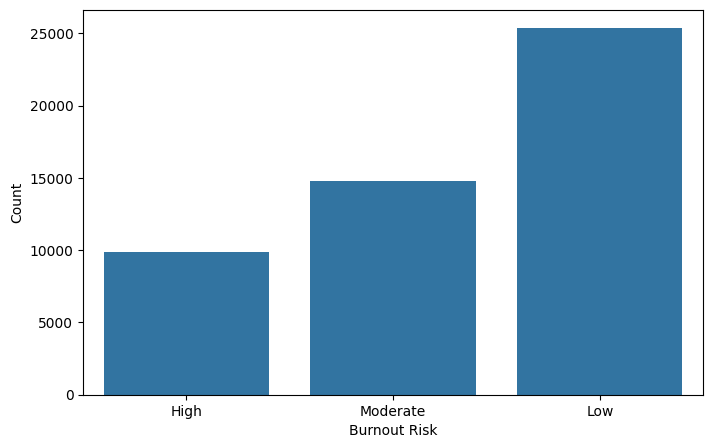

In [18]:
# Visualize the class balance of the target variable (Burnout_Risk)
plt.figure(figsize = (8, 5))
sns.countplot(data = mental_df, x = 'Burnout_Risk')
plt.xlabel('Burnout Risk')
plt.ylabel('Count')
plt.show()

In [19]:
# Categorical predictor columns only (exclude the target itself)
cat_hyp = [col for col in cat_cols if col != 'Burnout_Risk']
cat_hyp

['Gender',
 'Country',
 'Occupation',
 'Education_Level',
 'Employment_Status',
 'Remote_Work',
 'Sleep_Quality',
 'Stress_Level',
 'Exercise_Frequency',
 'Alcohol_Consumption',
 'Smoking',
 'Healthy_Diet',
 'Chronic_Stress',
 'Family_History_Mental_Illness',
 'Therapy_Attendance',
 'Support_System',
 'Mental_Health_Status',
 'AI_Wellness_Recommendation']

### 2.2 Categorical Features vs Target (Chi-square test)

In [20]:
# Chi-square test of independence: does each categorical feature have a
# statistically significant relationship with Burnout_Risk?
desired_cols = []
for col in cat_hyp:
    H0 = f'There is no relationship between Burnout and {col}'
    H1 = f'There is a significant relationship between Burnout and {col}'
    alpha = 0.05
    
    # Build a contingency table of feature vs target
    crosstab = pd.crosstab(mental_df[col], mental_df['Burnout_Risk'])

    chi2, p_value, dof, expected = chi2_contingency(crosstab)
    print(f"P-value:              {p_value:.4f}")
    
    if p_value<alpha:
        # Significant relationship found -> keep this feature
        print(f"Reject H0 that '{H0}'")
        desired_cols.append(col)
    else:
        # No significant relationship -> feature likely not useful
        print(f"Fail to Reject H0 that '{H0}'")
                           
desired_cols

P-value:              0.4959
Fail to Reject H0 that 'There is no relationship between Burnout and Gender'
P-value:              0.3512
Fail to Reject H0 that 'There is no relationship between Burnout and Country'
P-value:              0.2563
Fail to Reject H0 that 'There is no relationship between Burnout and Occupation'
P-value:              0.6363
Fail to Reject H0 that 'There is no relationship between Burnout and Education_Level'
P-value:              0.4680
Fail to Reject H0 that 'There is no relationship between Burnout and Employment_Status'
P-value:              0.4575
Fail to Reject H0 that 'There is no relationship between Burnout and Remote_Work'
P-value:              0.0000
Reject H0 that 'There is no relationship between Burnout and Sleep_Quality'
P-value:              0.0000
Reject H0 that 'There is no relationship between Burnout and Stress_Level'
P-value:              0.4304
Fail to Reject H0 that 'There is no relationship between Burnout and Exercise_Frequency'
P-value

['Sleep_Quality',
 'Stress_Level',
 'Healthy_Diet',
 'Chronic_Stress',
 'Mental_Health_Status']

### 2.3 Numeric Features Overview

In [21]:
# Numeric predictor columns (exclude categoricals and the ID column)
num_cols = [col for col in mental_df.columns if col not in cat_cols and col != 'Person_ID']
num_cols

['Age',
 'Monthly_Income_USD',
 'Work_Hours_Per_Week',
 'Job_Satisfaction',
 'Work_Life_Balance',
 'Sleep_Hours',
 'Anxiety_Score',
 'Depression_Score',
 'Mood_Score',
 'Emotional_Stability',
 'Physical_Activity_Hours',
 'Meditation_Minutes',
 'Screen_Time_Hours',
 'Social_Media_Hours',
 'Gaming_Hours',
 'Coffee_Cups_Per_Day',
 'Life_Satisfaction',
 'Productivity_Score',
 'Absenteeism_Days',
 'Burnout_Score']

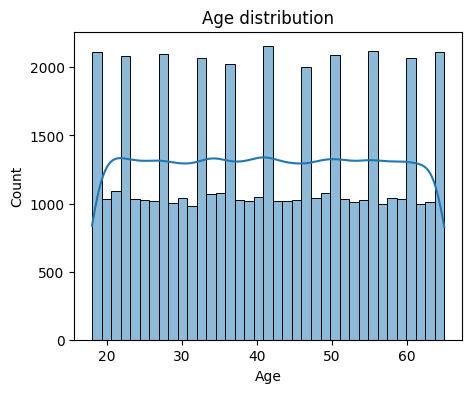

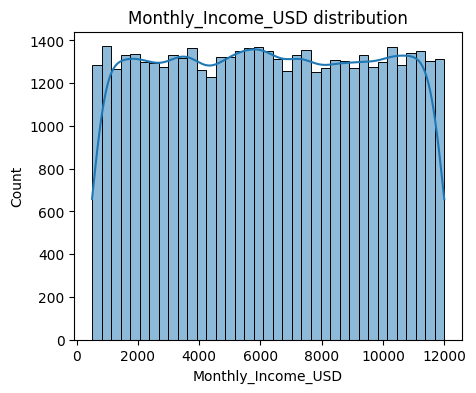

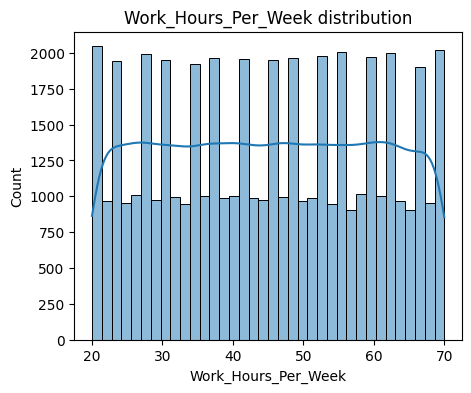

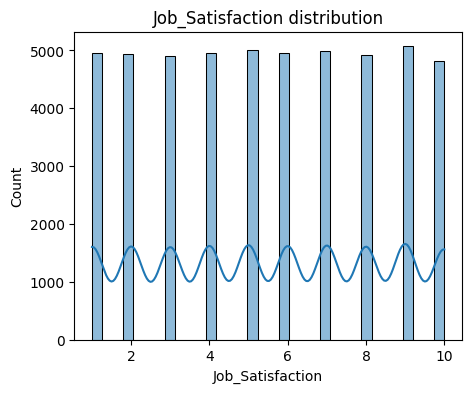

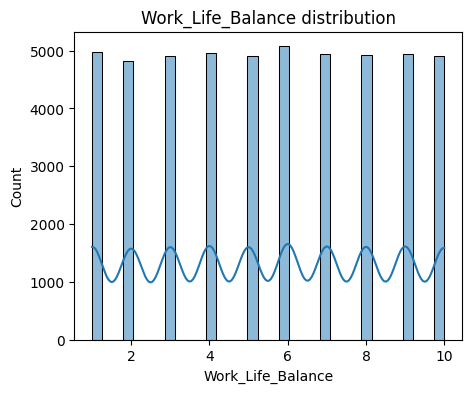

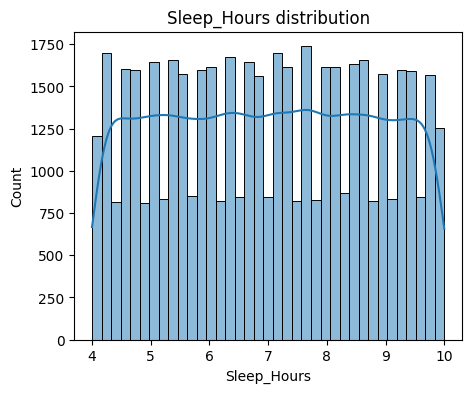

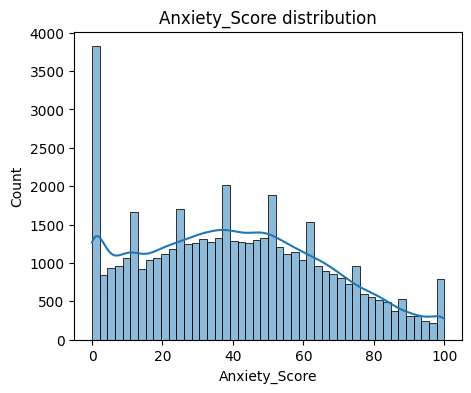

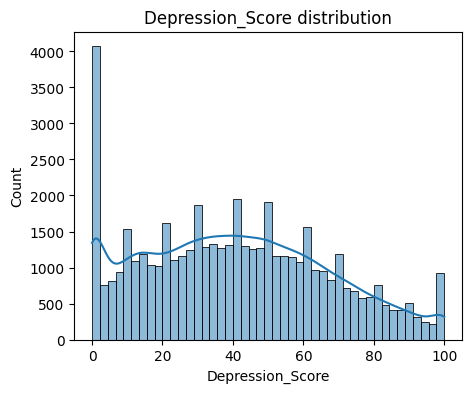

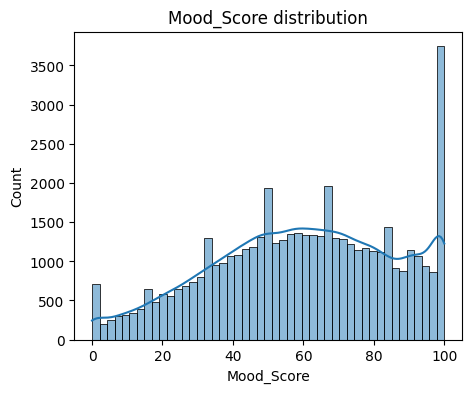

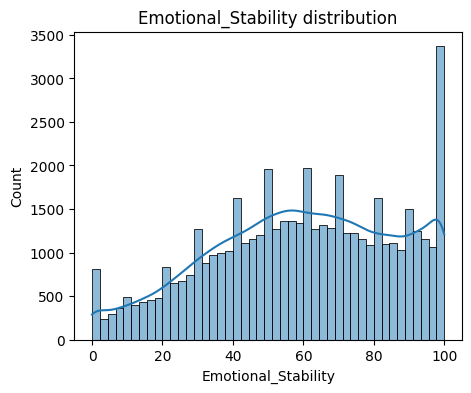

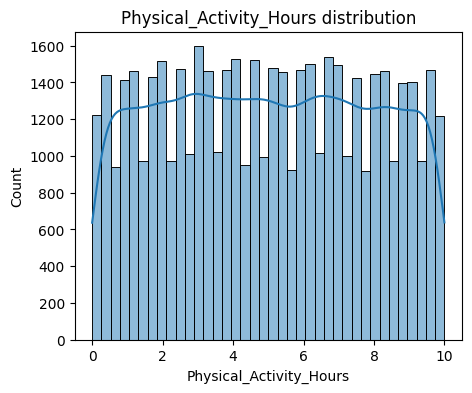

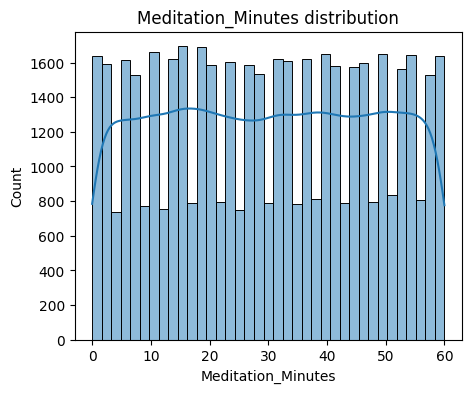

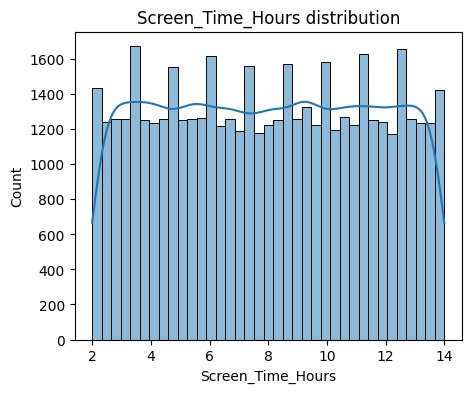

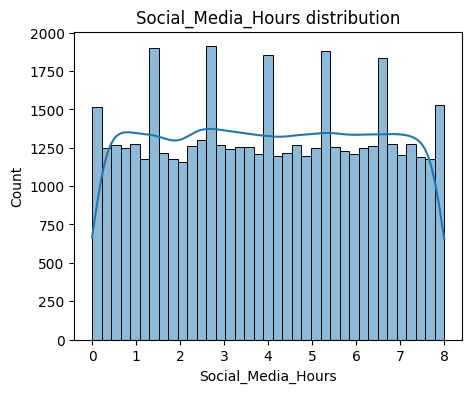

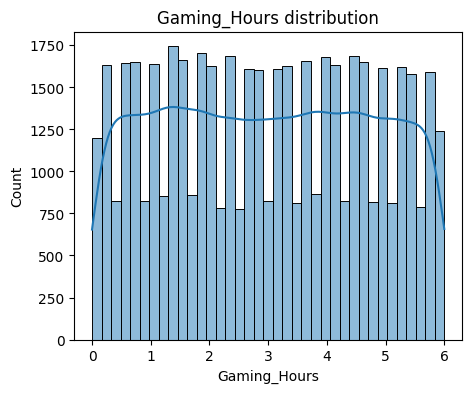

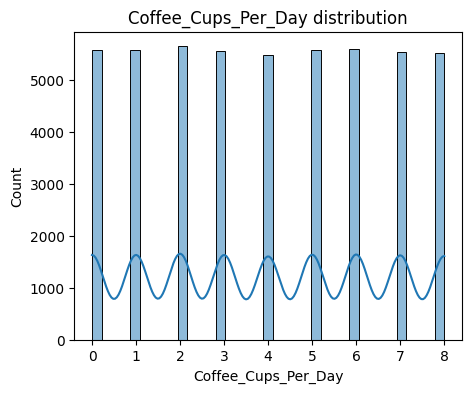

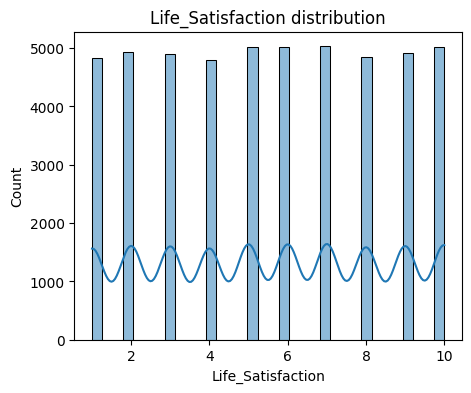

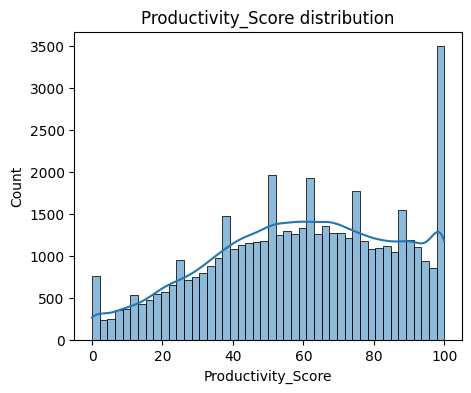

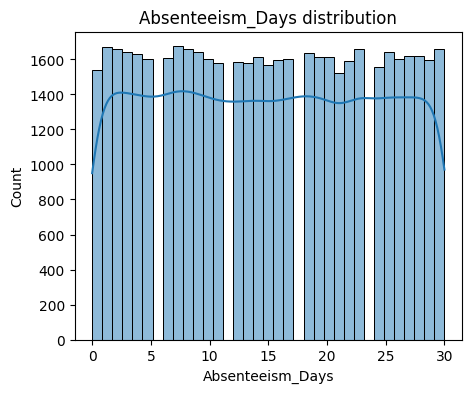

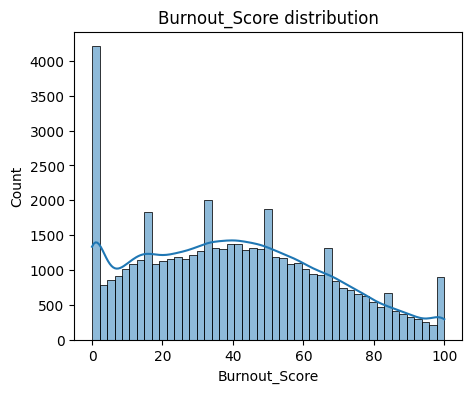

In [22]:
# Plot the distribution of every numeric column to check shape, skew, outliers
for col in num_cols:
    plt.figure(figsize = (5, 4))
    sns.histplot(data = mental_df, x = col, kde = True)
    plt.xlabel(f'{col}')
    plt.title(f'{col} distribution')
    plt.show

## 4. Feature Hypothesis Testing
Check each feature for a statistically significant relationship with `Burnout_Risk` before including it in the model.

In [23]:
# Work on a copy so the original DataFrame stays untouched
mental_df_copy = mental_df.copy()

In [24]:
# Drop rows with any missing values, needed for the Kruskal-Wallis test below
mental_copy = mental_df_copy.dropna()

In [25]:
# Kruskal-Wallis test: does the distribution of each numeric feature differ
# significantly across the Burnout_Risk groups (Low/Moderate/High)?
for col in num_cols:
    H0 = f"There is no difference in the distribution of {col} across Burnout Risk"
    H1 = f"At least one Burnout group has a different distribution of {col}"

    alpha = 0.05
    # Split the column's values into one array per Burnout_Risk group
    num_groups = [group[col].values for name, group in mental_copy.groupby('Burnout_Risk')
    ]
    H_stat, p_value = kruskal(*num_groups)

    if p_value < alpha:
        # Significant difference across groups -> keep this feature
        print(f"Reject the null hypothesis that '{H0}''")
        print(f"P-Value: {p_value}")
        desired_cols.append(col)
    else:
        # No significant difference -> feature likely not useful
        print(f"Fail to reject the null hypothesis that '{H0}'")
        print(f"P-Value: {p_value}")

desired_cols

Fail to reject the null hypothesis that 'There is no difference in the distribution of Age across Burnout Risk'
P-Value: 0.38103912985585
Fail to reject the null hypothesis that 'There is no difference in the distribution of Monthly_Income_USD across Burnout Risk'
P-Value: 0.6577820540618031
Reject the null hypothesis that 'There is no difference in the distribution of Work_Hours_Per_Week across Burnout Risk''
P-Value: 0.0
Fail to reject the null hypothesis that 'There is no difference in the distribution of Job_Satisfaction across Burnout Risk'
P-Value: 0.7413753583544478
Fail to reject the null hypothesis that 'There is no difference in the distribution of Work_Life_Balance across Burnout Risk'
P-Value: 0.7603928333350538
Reject the null hypothesis that 'There is no difference in the distribution of Sleep_Hours across Burnout Risk''
P-Value: 0.0
Reject the null hypothesis that 'There is no difference in the distribution of Anxiety_Score across Burnout Risk''
P-Value: 0.0
Reject the n

['Sleep_Quality',
 'Stress_Level',
 'Healthy_Diet',
 'Chronic_Stress',
 'Mental_Health_Status',
 'Work_Hours_Per_Week',
 'Sleep_Hours',
 'Anxiety_Score',
 'Depression_Score',
 'Mood_Score',
 'Emotional_Stability',
 'Physical_Activity_Hours',
 'Meditation_Minutes',
 'Screen_Time_Hours',
 'Coffee_Cups_Per_Day',
 'Productivity_Score',
 'Burnout_Score']

In [26]:
# Drop Burnout_Score since it's essentially a numeric proxy for the target
# itself (Burnout_Risk is derived from it) and would leak the answer
desired_cols.remove('Burnout_Score')
desired_cols

['Sleep_Quality',
 'Stress_Level',
 'Healthy_Diet',
 'Chronic_Stress',
 'Mental_Health_Status',
 'Work_Hours_Per_Week',
 'Sleep_Hours',
 'Anxiety_Score',
 'Depression_Score',
 'Mood_Score',
 'Emotional_Stability',
 'Physical_Activity_Hours',
 'Meditation_Minutes',
 'Screen_Time_Hours',
 'Coffee_Cups_Per_Day',
 'Productivity_Score']

## 3. Train / Validation / Test Split
Using only the features that passed the significance tests above.

In [27]:
# Final feature matrix X (only the statistically-significant columns) and target y
X = mental_df[desired_cols]
y = mental_df['Burnout_Risk']

In [28]:
# First split: 80% train, 20% held out (to be split further into val/test)
# stratify=y keeps class proportions consistent across splits
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size = 0.2, random_state = 42, stratify = y)

In [29]:
# Second split: divide the 20% held-out chunk evenly into validation and test (10% each)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size = 0.5, random_state = 42, stratify = y_temp)

In [30]:
# Sanity-check the resulting shapes of each split
print(X.shape)
print(X_train.shape)
print(X_test.shape)
print(X_temp.shape)
print(X_val.shape)

(50000, 16)
(40000, 16)
(5000, 16)
(10000, 16)
(5000, 16)


### 4.1 Separate features into numerical and categorical
Different preprocessing is needed for each type before modeling.

In [31]:
# Split feature columns by dtype so numeric and categorical features can be
# preprocessed differently
num_features = X.select_dtypes(include = ['int', 'float']).columns.to_list()
cat_features = X.select_dtypes(include = ['object']).columns.to_list()
print(num_features)
print(cat_features)

['Work_Hours_Per_Week', 'Sleep_Hours', 'Anxiety_Score', 'Depression_Score', 'Mood_Score', 'Emotional_Stability', 'Physical_Activity_Hours', 'Meditation_Minutes', 'Screen_Time_Hours', 'Coffee_Cups_Per_Day', 'Productivity_Score']
['Sleep_Quality', 'Stress_Level', 'Healthy_Diet', 'Chronic_Stress', 'Mental_Health_Status']


### 4.2 Encode the target column
Convert the text labels (`Low`/`Moderate`/`High`) into integers the model can use.

In [32]:
# Encode the text target labels (Low/Moderate/High) into integers 0/1/2
# Fit only on the training labels, then reuse the same mapping for val/test
encoder = LabelEncoder()
y_train_encoded = encoder.fit_transform(y_train)
y_test_encoded = encoder.transform(y_test)
y_val_encoded = encoder.transform(y_val)

### 4.3 Build preprocessing pipelines
One pipeline for numeric features (impute + scale), one for categorical features (impute + one-hot encode).

In [33]:
# Numeric pipeline: fill missing values with the median, then standardize
num_pipeline = Pipeline(steps = [
    ('imputer', SimpleImputer(strategy = 'median')),
    ('scaler', StandardScaler())
])

# Categorical pipeline: fill missing values with the most frequent category,
# then one-hot encode (ignoring any unseen categories at inference time)
cat_pipeline = Pipeline(steps = [
    ('imputer', SimpleImputer(strategy = 'most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown = 'ignore'))
])

### 4.4 Combine the pipelines
Use a `ColumnTransformer` to apply the right pipeline to the right columns.

In [34]:
# Combine the numeric and categorical pipelines into a single preprocessor
# that applies the right transformation to the right columns
preprocessor = ColumnTransformer(transformers =[
    ('num', num_pipeline, num_features),
    ('cat', cat_pipeline, cat_features)
    
])

In [35]:
# Fit the preprocessor on training data only, then transform all three splits
# (val/test must only be transformed, never fitted, to avoid data leakage)
X_train_preprocessed = preprocessor.fit_transform(X_train)
X_test_preprocessed = preprocessor.transform(X_test)
X_val_preprocessed = preprocessor.transform(X_val)

## 5. Build the Neural Network

### 5.1 Model Architecture

In [36]:
# Define a feedforward neural network for 3-class classification
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape = (X_train_preprocessed.shape[1],)),                                   # input layer sized to the number of preprocessed features
    tf.keras.layers.Dense(64, activation = 'relu', kernel_regularizer = tf.keras.regularizers.l1(0.001)),  # hidden layer 1, with L1 regularization to reduce overfitting
    tf.keras.layers.Dense(32, activation = 'relu'),                                                    # hidden layer 2
    tf.keras.layers.Dense(32, activation = 'relu'),                                                    # hidden layer 3
    tf.keras.layers.Dense(3, activation = 'softmax')                                                   # output layer: 3 classes (Low/Moderate/High), softmax gives class probabilities
])

2026-09-13 15:19:48.119411: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [37]:
# Print the model architecture: layer shapes and parameter counts
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,899 (19.14 KB)

 Trainable params: 4,899 (19.14 KB)

 Non-trainable params: 0 (0.00 B)

### 5.1 Compile the model

In [38]:
# Compile the model: Adam optimizer, sparse categorical crossentropy since
# labels are integers (not one-hot), and track accuracy during training
model.compile(optimizer = 'adam', loss = 'sparse_categorical_crossentropy', metrics = ['accuracy'])

In [39]:
# Train the model, validating on the held-out validation set after every epoch
model_fit = model.fit(
    X_train_preprocessed,
    y_train_encoded,
    validation_data = (X_val_preprocessed, y_val_encoded),
    epochs = 50,
    batch_size = 32,
    verbose = 1
)

Epoch 1/50
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9719 - loss: 0.1880 - val_accuracy: 0.9878 - val_loss: 0.0760
Epoch 2/50
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9859 - loss: 0.0665 - val_accuracy: 0.9878 - val_loss: 0.0537
Epoch 3/50
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9860 - loss: 0.0576 - val_accuracy: 0.9878 - val_loss: 0.0504
Epoch 4/50
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9860 - loss: 0.0543 - val_accuracy: 0.9878 - val_loss: 0.0462
Epoch 5/50
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9860 - loss: 0.0525 - val_accuracy: 0.9878 - val_loss: 0.0456
Epoch 6/50
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9860 - loss: 0.0511 - val_accuracy: 0.9878 - val_loss: 0.0452
Epoch 7/50
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9860 - loss: 0.0502 - val_accuracy: 0.9878 - val_loss: 0.0451
Epoch 8/50
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9859 - loss: 0.0509 - 

### 5.2 Training history
Plot accuracy and loss over epochs to check learning progress and overfitting.

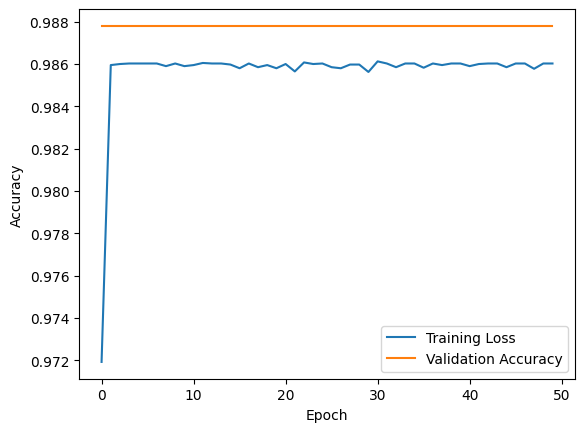

In [40]:
# Plot training vs. validation accuracy across epochs to check for overfitting
plt.plot(model_fit.history['accuracy'], label = 'Training Loss')
plt.plot(model_fit.history['val_accuracy'], label = 'Validation Accuracy')

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

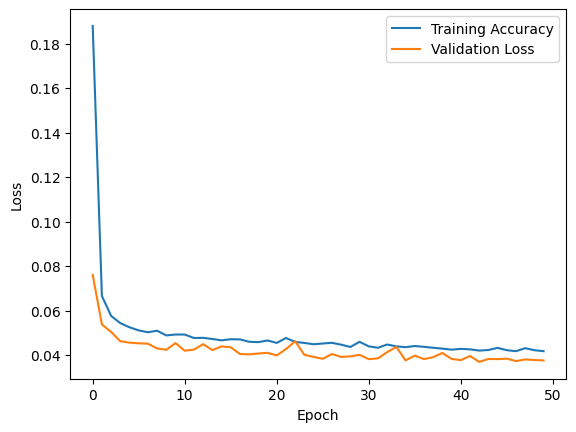

In [41]:
# Plot training vs. validation loss across epochs to check for overfitting
plt.plot(model_fit.history['loss'], label = 'Training Accuracy')
plt.plot(model_fit.history['val_loss'], label = 'Validation Loss')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

## 6. Evaluate on the Test Set

In [42]:
# Predict class probabilities for the test set (one probability per class, per row)
class_prediction = model.predict(X_test_preprocessed)
class_prediction

157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


array([[2.35132497e-10, 1.18113256e-14, 9.99999940e-01],
       [1.66314440e-09, 9.99999940e-01, 1.92756087e-08],
       [1.18029666e-11, 1.67305084e-14, 9.99999940e-01],
       ...,
       [9.17164513e-08, 9.99998987e-01, 8.29872135e-07],
       [1.31438312e-03, 9.98667717e-01, 1.78998653e-05],
       [1.06061702e-08, 9.99999821e-01, 7.23195583e-08]], dtype=float32)

In [43]:
# Convert probabilities to final class predictions by taking the highest-probability class
y_pred = np.argmax(class_prediction, axis = 1)
y_pred

array([2, 1, 2, ..., 1, 1, 1])

In [44]:
# Full classification report: precision, recall, f1-score per class on the test set
print(classification_report(y_test_encoded, y_pred, target_names = encoder.classes_))

              precision    recall  f1-score   support

        High       0.94      1.00      0.97       985
         Low       1.00      1.00      1.00      2537
    Moderate       1.00      0.96      0.98      1478

    accuracy                           0.99      5000
   macro avg       0.98      0.99      0.98      5000
weighted avg       0.99      0.99      0.99      5000

